# Heuers' statistical Football model

The following implementation aims to recreate the Football model of Prof. Dr. Andreas Heuer.

In [159]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from functools import cache

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
SEED = 1893

np.random.seed(SEED)

In [160]:
# Helperfunctions
def plot_per_season_per_country(df, y, fit_reg=True):
    seasons = [14, 15, 16, 17, 18]
    sns.lmplot(x="season", y=y,
               hue="country", data=df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    sumed_df = pd.DataFrame()
    sumed_df["season"] = seasons
    total = []
    for season in seasons:
        total.append(np.sum(df.groupby(["season"]).get_group(
            season)[y]) / NUM_OF_COUNTRIES)
    sumed_df[y] = total
    sns.lmplot(x="season", y=y,
               data=sumed_df, ci=None, fit_reg=fit_reg)
    plt.xticks(seasons, ["14-15", "15-16", "16-17", "17-18", "18-19"])
    plt.show()

def closed_form_solution(X, y):
    # alternative: np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, y))
    return np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))


## Step 1 - Homefieldadvantage (per country and season)

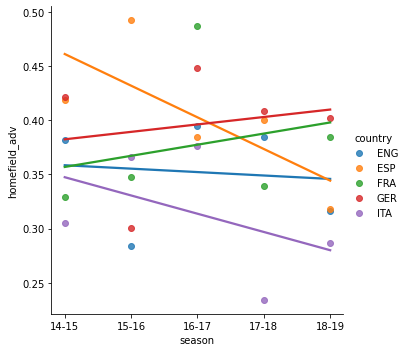

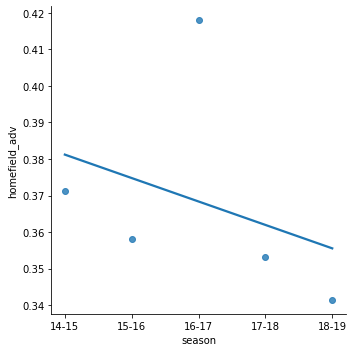

In [161]:
df_homefield = pd.read_csv('data/homefield_adv.csv', sep=';')
plot_per_season_per_country(df_homefield, y="homefield_adv")

Homefield advantage tends to have high variance, a clear trend per country or season is not visible.
Therefor homefield advantage will be modeled as an constant of the average of hometeamgoals - awayteamgoals

In [162]:
avg_homefield_adv = np.sum(df_homefield["homefield_adv"]) / NUM_OF_SEASONS
print("Average homefield advantage on all games:", avg_homefield_adv)


Average homefield advantage on all games: 0.36837358101135187


In [163]:
df_country_season_homefield_adv = pd.read_csv(
    "data/country_season_homefield_adv.csv", sep=";")
# df_country_season_homefield_adv['bias'] = 1

noise = np.random.normal(
    avg_homefield_adv, 0.1, df_country_season_homefield_adv.shape[0] * 3)

for index, row in df_country_season_homefield_adv.iterrows():
    if row["hf_adv_actual"] == 0:
        df_country_season_homefield_adv.at[index,
                                           "hf_adv_actual"] = noise[index]
    if row["hf_adv_current_season"] == 0:
        df_country_season_homefield_adv.at[index,
                                           "hf_adv_current_season"] = noise[df_country_season_homefield_adv.shape[0] + index]
    if row["hf_adv_last_three_seasons"] == 0:
        df_country_season_homefield_adv.at[index,
                                           "hf_adv_last_three_seasons"] = noise[df_country_season_homefield_adv.shape[0] * 2 + index]

df_country_season_homefield_adv


,country,season,matchnumber,hf_adv_actual,hf_adv_current_season,hf_adv_last_three_seasons
0,ENG,14,0,0.367303,0.476522,0.459603
1,ENG,14,1,-0.600000,-0.300000,0.476006
2,ENG,14,2,0.700000,0.033333,0.374316
3,ENG,14,3,-0.400000,-0.075000,0.311211
4,ENG,14,4,0.600000,0.060000,0.344879
...,...,...,...,...,...,...
950,ITA,18,34,0.500000,0.262857,0.317094
951,ITA,18,35,-0.300000,0.247222,0.317094
952,ITA,18,36,0.300000,0.248649,0.317094
953,ITA,18,37,1.000000,0.268421,0.317094


In [181]:

@cache
def h_country_season_homefield_adv(country, season, matchnumber):
    sub_df = df_country_season_homefield_adv.query(
        f"country == '{country}' and season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["hf_adv_last_three_seasons",
                "hf_adv_current_season"]].values  # no bias
    y = sub_df["hf_adv_actual"].values

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_country_season_homefield_adv.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["hf_adv_last_three_seasons",
                      "hf_adv_current_season"]].values  # no bias

    return np.dot(w, input.T)[0]


print("Homefield advantage:", h_country_season_homefield_adv("ENG", 14, 1))


Homefield advantage: 13.669718453742174


## Step 2 - Goalamount per match (per country and season)

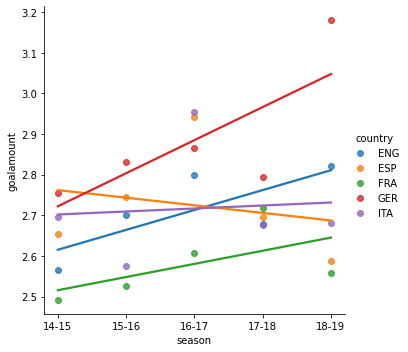

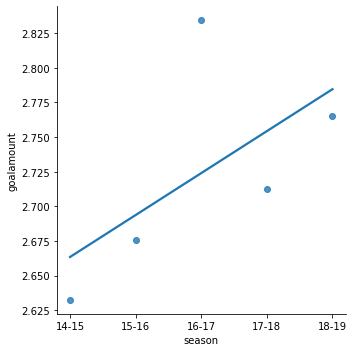

In [165]:
df_goalamount = pd.read_csv('data/goalamount.csv', sep=';')
plot_per_season_per_country(df_goalamount, "goalamount")

there are higher scored countrys as well as lower scoring ones
for now the goalamount will be modeled as a constant

In [166]:
avg_goalamount = np.sum(df_goalamount["goalamount"]) / NUM_OF_SEASONS
print("Average goalamount of all games:", avg_goalamount)

Average goalamount of all games: 2.724046095631235


In [167]:
df_country_season_goalamount = pd.read_csv(
    "data/country_season_goalamount.csv", sep=";")
# df_country_season_goalamount['bias'] = 1

noise = np.random.normal(
    avg_goalamount, 0.1, df_country_season_goalamount.shape[0] * 3)


for index, row in df_country_season_goalamount.iterrows():
    if row["ga_actual"] == float(0):
        df_country_season_goalamount.at[index, "ga_actual"] = noise[index]
    if row["ga_current_season"] == float(0):
        df_country_season_goalamount.at[index,
                                        "ga_current_season"] = noise[df_country_season_goalamount.shape[0] + index]
    if row["ga_last_three_seasons"] == float(0):
        df_country_season_goalamount.at[index,
                                        "ga_last_three_seasons"] = noise[df_country_season_goalamount.shape[0] * 2 + index]

df_country_season_goalamount


,country,season,matchnumber,ga_actual,ga_current_season,ga_last_three_seasons
0,ENG,14,0,2.720757,2.609005,2.695870
1,ENG,14,1,2.600000,2.639121,2.770074
2,ENG,14,2,2.300000,2.600000,2.544671
3,ENG,14,3,3.200000,2.450000,2.669460
4,ENG,14,4,3.000000,2.700000,2.831483
...,...,...,...,...,...,...
950,ITA,18,34,2.300000,2.663636,2.735965
951,ITA,18,35,2.900000,2.652941,2.735965
952,ITA,18,36,3.100000,2.660000,2.735965
953,ITA,18,37,2.800000,2.672222,2.735965


In [168]:

@cache
def h_country_season_goalamount(country, season, matchnumber):
    sub_df = df_country_season_goalamount.query(
        f"country == '{country}' and season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["ga_last_three_seasons",
                "ga_current_season"]].values  # no bias
    y = sub_df["ga_actual"].values

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_country_season_goalamount.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["ga_last_three_seasons",
                      "ga_current_season"]].values  # no bias
    return np.dot(w, input.T)[0]


print("Goalamount:", h_country_season_goalamount("GER", 18, 34))

Goalamount: 3.1537235763697167


## Step 3: Teamstrength and expected goaldifference

In the first season (14/15) every team is treated promoter.

In [169]:
df_matches = pd.read_csv('data/matches.csv', sep=';')

noise = np.random.normal(0, 0.1, df_matches.shape[0] * 5)

for index, row in df_matches.iterrows():
    if row["curr_chancediff"] == 0:
        df_matches.at[index, "curr_chancediff"] = noise[index]
    if row["past_chancediff_combined"] == 0:
        df_matches.at[index,
                           "past_chancediff_combined"] = noise[df_matches.shape[0] + index]
    if row["past_chanceamount"] == 0:
        df_matches.at[index,
                           "past_chanceamount"] = noise[df_matches.shape[0] * 2 + index]
    if row["actual_goaldiff"] == 0:
        df_matches.at[index,
                           "actual_goaldiff"] = noise[df_matches.shape[0] * 3 + index]
    if row["actual_goalamount"] == 0:
        df_matches.at[index,
                           "actual_goalamount"] = noise[df_matches.shape[0] * 4 + index]

df_matches


,country,season,matchnumber,teamname,curr_chancediff,past_chancediff_combined,past_chanceamount,market_value_ln_relative,actual_goalamount,actual_goaldiff
0,ENG,14,0,Queens Park Rangers,-0.112741,-0.237198,-0.024795,-0.392415,0,0
1,ENG,14,0,Hull,0.034612,0.148424,0.116203,-0.348740,0,0
2,ENG,14,0,Newcastle,0.016114,-0.011413,0.084268,-0.169272,0,0
3,ENG,14,0,Man City,0.046209,0.121347,-0.152838,1.002768,0,0
4,ENG,14,0,Burnley,-0.057444,-0.262614,0.056804,-1.140622,0,0
...,...,...,...,...,...,...,...,...,...,...
18745,ITA,18,38,Napoli,3.526316,5.293421,337.333333,1.070083,5,-1
18746,ITA,18,38,Inter,2.210526,2.380263,256.666667,1.024225,3,1
18747,ITA,18,38,Empoli,-2.421053,-3.058772,167.333333,-0.738824,3,-1
18748,ITA,18,38,Cagliari,-2.578947,-1.972368,183.333333,-0.358838,3,-1


In [170]:
@cache
def h_teamstrength(country, season, matchnumber, teamname):
    sub_df = df_matches.query(
        f"country == '{country}' and season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chancediff_combined",
                "curr_chancediff", "market_value_ln_relative"]].values  # no bias
    y = sub_df["actual_goaldiff"].values

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_matches.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")
    input = input_df[["past_chancediff_combined",
                      "curr_chancediff", "market_value_ln_relative"]].values  # no bias

    return np.dot(w, input.T)[0]

#TODO: Homefield adv correction
#TODO: Effective chancediff
#TODO: Current fitness value is missing 
#TODO: Verwertungsfaktor on chancediff is missing

print("Teamstrength:", h_teamstrength("GER", 17, 18, "Borussia Dortmund"))


Teamstrength: 0.8297161715408015


## Step 4: Specialty for promoters

In [171]:
#TODO: Implement special correction of teamstrength for promoters

## Step 5: Expected goalamount per match

In [172]:
@cache
def h_goalamount_from_avg_per_match(country, season, matchnumber, teamname):
    sub_df = df_matches.query(
        f"country == '{country}' and season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chanceamount"]].values  # no bias
    y = []
    for index, row in sub_df.iterrows():
        # y.append(row["actual_goalamount"] - h_country_season_goalamount(country, season, row["matchnumber"] + 1))
        if row["matchnumber"] == 0:
            y.append(row["actual_goalamount"] - avg_goalamount)
        else:
            y.append(row["actual_goalamount"] - h_country_season_goalamount(country, season, row["matchnumber"]))

    w = closed_form_solution(X, y)
    #print("weights:", w)

    input_df = df_matches.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")
    input = input_df[["past_chanceamount"]].values  # no bias

    return np.dot(w, input.T)[0]

#TODO: Homefield adv correction
#TODO: Effective chancediff missing

print("Goalamount from avg:", h_goalamount_from_avg_per_match("ENG", 18, 20, "Man City"))



Goalamount from avg: 0.08143281249201303


## Step 6: Predicted Goals

In [173]:
def predicted_goals(country, season, matchnumber, hometeam, awayteam):
    goalamount = h_goalamount_from_avg_per_match(
        country, season, matchnumber, hometeam) + h_goalamount_from_avg_per_match(country, season, matchnumber, awayteam) + h_country_season_goalamount(country, season, matchnumber)
    goaldiff = h_country_season_homefield_adv(country, season, matchnumber) + h_teamstrength(country, season, matchnumber, hometeam) - h_teamstrength(country, season, matchnumber, awayteam)
    return (goalamount, goaldiff)


amount, diff = predicted_goals("GER", 17, 34, "Freiburg", "Augsburg")

if diff < 0:
    home_score = (amount - diff) / 2
    away_score = home_score + (-diff)
else:
    away_score = (amount - diff) / 2
    home_score = away_score + diff

print("Prediction GER 17-18 34 Freiburg - Augsburg:",
      str(home_score)[0:4] + " : " + str(away_score)[0:4])


Prediction GER 17-18 34 Freiburg - Augsburg: 2.07 : 1.78


## Step 7: Dependence on matchnumber

In [174]:
def matchnumber_goalamount_multiplier(country, matchnumber):
    # Uncertain
    if country == 'GER':
        if matchnumber < 18:
            return 1.02
        elif matchnumber < 31:
            return 0.95
        else:
            return 1.2
    else:
        if matchnumber < 19:
            return 1.02
        elif matchnumber < 35:
            return 0.95
        else:
            return 1.2


## Final: Full run on dataset to measure goalamount and goaldifference error

In [175]:
def predict(country, season, matchnumber, hometeam, awayteam):
    amount, diff = predicted_goals(country, season, matchnumber, hometeam, awayteam)

    if diff < 0:
        home_score = (amount - diff) / 2
        away_score = home_score + (-diff)
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    home_score *= matchnumber_goalamount_multiplier(country, matchnumber)
    away_score *= matchnumber_goalamount_multiplier(country, matchnumber)

    return f"{str(home_score)[0:4]} : {str(away_score)[0:4]}"


In [176]:

country, season, matchnumber, hometeam, awayteam = "GER", 17, 24, "Bayern", "Hertha Berlin" # "Werder Bremen", "Hamburg"

print(f"Prediction {country} {season} {matchnumber} {hometeam} - {awayteam}:",
      predict(country, season, matchnumber, hometeam, awayteam))


Prediction GER 17 24 Bayern - Hertha Berlin: 2.76 : 1.63


In [183]:
# For match in Dataset run prediction and measure error
for index, row in df_matches.iterrows():
    if row["matchnumber"] == 0:
         continue
    if index % 2 == 0:
        hometeam = row["teamname"]
        continue
    else:
        awayteam = row["teamname"]
        print(row["country"], row["season"], row["matchnumber"], hometeam, awayteam, predict(
            row["country"], row["season"], row["matchnumber"], hometeam, awayteam))


ENG 14 1 Queens Park Rangers Hull 8.72 : -5.2
ENG 14 1 Newcastle Man City 8.19 : -5.7
ENG 14 1 Burnley Chelsea 8.39 : -5.5
ENG 14 1 Arsenal Crystal Palace 8.43 : -5.5
ENG 14 1 West Ham Tottenham 8.66 : -5.2
ENG 14 1 Leicester Everton 8.43 : -5.5
ENG 14 1 Man Utd Swansea 7.66 : -6.2
ENG 14 1 West Brom Sunderland 8.41 : -5.5
ENG 14 1 Liverpool Southampton 8.18 : -5.7
ENG 14 1 Stoke Aston Villa 7.75 : -6.1
ENG 14 2 Sunderland Man Utd 2.22 : 3.18
ENG 14 2 Aston Villa Newcastle 1.70 : 1.83
ENG 14 2 Tottenham Queens Park Rangers 1.62 : 1.27
ENG 14 2 Swansea Burnley 1.80 : 1.46
ENG 14 2 Hull Stoke 2.12 : 2.25
ENG 14 2 Southampton West Brom 2.31 : 2.03
ENG 14 2 Everton Arsenal 1.91 : 2.47
ENG 14 2 Crystal Palace West Ham 1.84 : 2.16
ENG 14 2 Chelsea Leicester 1.74 : 0.89
ENG 14 2 Man City Liverpool 1.92 : 1.80
ENG 14 3 West Ham Southampton 1.43 : 1.32
ENG 14 3 Burnley Man Utd 2.06 : 3.47
ENG 14 3 Swansea West Brom 1.50 : 1.26
ENG 14 3 Man City Stoke 1.89 : 0.86
ENG 14 3 Leicester Arsenal 2.20 